# DSCI 552 Homework 5

**Name:** Yilin Chen

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor

## 1. Decision Trees as Interpretable Models

### (a) 

Download the Accute Inflamations data from https://archive.ics.uci.edu/ml/datasets/Acute+Inflammations.

In [2]:
FEATURE_COLS = ["temperature", "nausea", "lumbar_pain", 
                "urine_pushing","micturition_pains", "burning_of_urethra"]
LABEL_COLS = ["bladder_inflammation", "nephritis"]

diagnosis = pd.read_csv("../data/Homework 5 Data/diagnosis.data", sep="\t", header=None, encoding="utf-16",
                        decimal=",", names=FEATURE_COLS + LABEL_COLS)

# convert yes/no to 1/0
yes_no_cols = FEATURE_COLS[1:] + LABEL_COLS
for col in yes_no_cols:
    diagnosis[col] = diagnosis[col].map({"no": 0, "yes": 1})

diagnosis.head()

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_of_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b)

Build a decision tree on the whole data set and plot it.

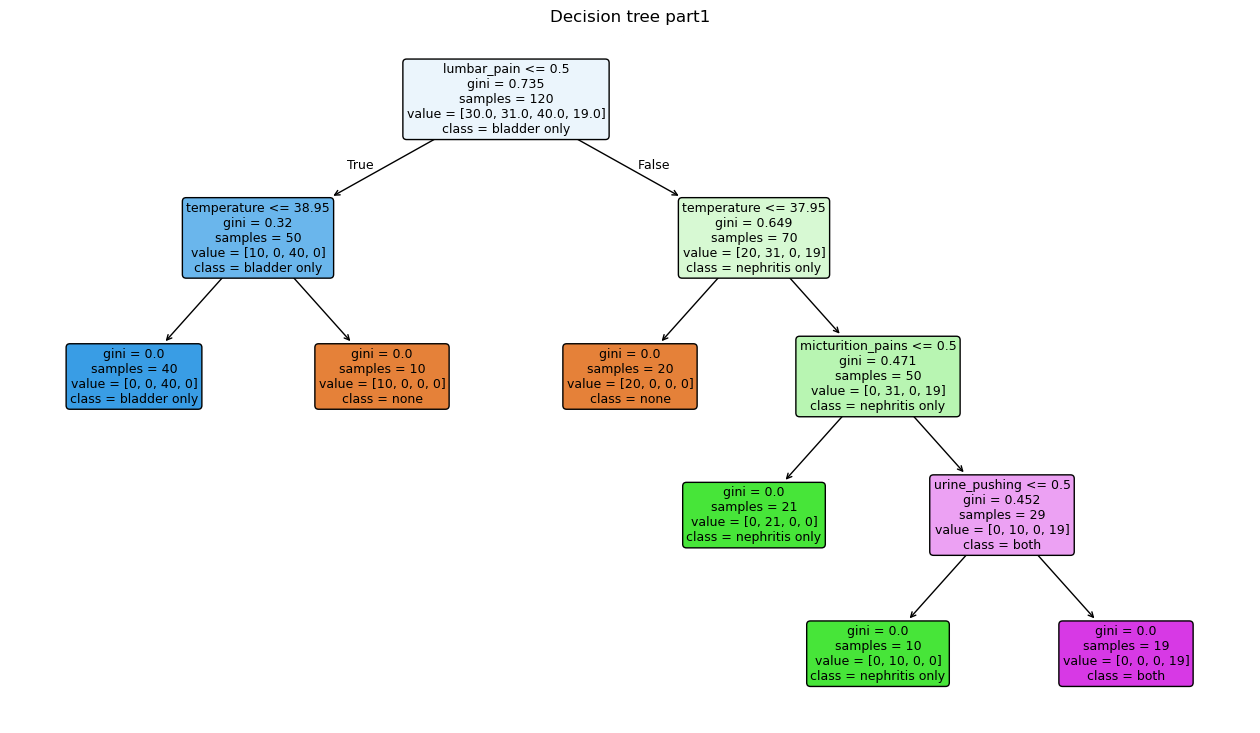

In [3]:
# Label powerset
CLASS_NAMES = ["none", "nephritis only", "bladder only", "both"]

def to_powerset(row):
    return 2 * row["bladder_inflammation"] + row["nephritis"]

X = diagnosis[FEATURE_COLS]
# map each label combination to one class
y = diagnosis.apply(to_powerset, axis=1)
# build tree, and train
full_tree = DecisionTreeClassifier(random_state=0)
full_tree.fit(X, y)
# plot decision tree
plt.figure(figsize=(16, 9))
plot_tree(full_tree, feature_names=FEATURE_COLS, class_names=CLASS_NAMES,
          filled=True, rounded=True, fontsize=9)
plt.title("Decision tree part1")
plt.show()

### (c)

Convert the decision rules into a set of IF-THEN rules.

In [4]:
# the code refered "data/Homework 5 Data/Simplifying Decision Tree Interpretability with Python & Scikit-learn - KDnuggets.pdf"
# print one IF-THEN rule per leaf
def tree_to_rules(tree, feature_names, class_names):
    left = tree.tree_.children_left
    right = tree.tree_.children_right
    threshold = tree.tree_.threshold
    features = [feature_names[i] for i in tree.tree_.feature]
    value = tree.tree_.value
    def recurse(node, conditions):
        if threshold[node] != -2:
            condition_left = features[node]+" <= "+str(round(threshold[node], 2))
            condition_right = features[node]+" > "+str(round(threshold[node], 2))
            recurse(left[node], conditions + [condition_left])
            recurse(right[node], conditions + [condition_right])
        else:
            # print IF-THEN rule 
            print("IF " + " AND ".join(conditions) + " THEN " + class_names[np.argmax(value[node])])
    recurse(0, [])

tree_to_rules(full_tree, FEATURE_COLS, CLASS_NAMES)

IF lumbar_pain <= 0.5 AND temperature <= 38.95 THEN bladder only
IF lumbar_pain <= 0.5 AND temperature > 38.95 THEN none
IF lumbar_pain > 0.5 AND temperature <= 37.95 THEN none
IF lumbar_pain > 0.5 AND temperature > 37.95 AND micturition_pains <= 0.5 THEN nephritis only
IF lumbar_pain > 0.5 AND temperature > 37.95 AND micturition_pains > 0.5 AND urine_pushing <= 0.5 THEN nephritis only
IF lumbar_pain > 0.5 AND temperature > 37.95 AND micturition_pains > 0.5 AND urine_pushing > 0.5 THEN both


### (d)

Use cost-complexity pruning to find a minimal decision tree and a set of decision rules with high interpretability.

In [5]:
# get candidates alpha
ccp_alphas = full_tree.cost_complexity_pruning_path(X, y).ccp_alphas
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

results = []
# evaluate each alpha
for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(random_state=0, ccp_alpha=alpha)
    cv_accuracy = cross_val_score(tree, X, y, cv=cv).mean()
    tree.fit(X, y)
    results.append({"ccp_alpha": alpha, "n_leaves": tree.get_n_leaves(), "cv_accuracy": cv_accuracy})

pruning_results = pd.DataFrame(results)
pruning_results

,ccp_alpha,n_leaves,cv_accuracy
0,0.000000,6,0.991667
1,0.098167,4,0.858333
2,0.133333,3,0.758333
3,0.182000,2,0.683333
4,0.222917,1,0.483333


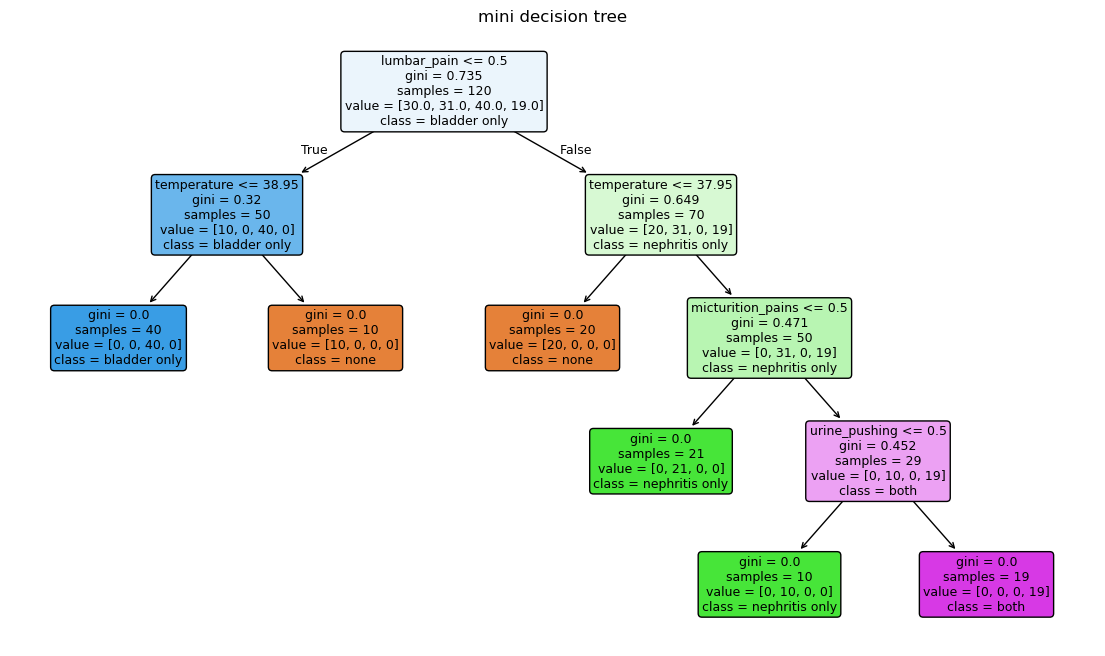

In [6]:
# according to the pruning_results table, the best alpha is 0
mini_tree = DecisionTreeClassifier(random_state=0, ccp_alpha=0)
mini_tree.fit(X, y)

plt.figure(figsize=(14, 8))
plot_tree(mini_tree, feature_names=FEATURE_COLS, class_names=CLASS_NAMES,
          filled=True, rounded=True, fontsize=9)
plt.title("mini decision tree")
plt.show()

In [7]:
tree_to_rules(mini_tree, FEATURE_COLS, CLASS_NAMES)

IF lumbar_pain <= 0.5 AND temperature <= 38.95 THEN bladder only
IF lumbar_pain <= 0.5 AND temperature > 38.95 THEN none
IF lumbar_pain > 0.5 AND temperature <= 37.95 THEN none
IF lumbar_pain > 0.5 AND temperature > 37.95 AND micturition_pains <= 0.5 THEN nephritis only
IF lumbar_pain > 0.5 AND temperature > 37.95 AND micturition_pains > 0.5 AND urine_pushing <= 0.5 THEN nephritis only
IF lumbar_pain > 0.5 AND temperature > 37.95 AND micturition_pains > 0.5 AND urine_pushing > 0.5 THEN both


**1(d) answer**

The full tree is already the minimal tree.

## 2. The LASSO and Boosting for Regression

### (a)

Download the Communities and Crime data from https://archive.ics.uci.edu/ml/datasets/Communities+and+Crime. Use the first 1495 rows of data as the training set and the rest as the test set.

In [8]:
# get column names from communities.names
column_names = []
with open("../data/Homework 5 Data/communities.names") as f:
    for line in f:
        if line.startswith("@attribute"):
            column_names.append(line.split()[1])

crime = pd.read_csv("../data/Homework 5 Data/communities.data", header=None, names=column_names, na_values="?")

train = crime.iloc[:1495]
test = crime.iloc[1495:]
print(train.shape, test.shape)

(1495, 128) (499, 128)


### (b)

The data set has missing values. Use a data imputation technique to deal with the missing values in the data set. The data description mentions some features are nonpredictive. Ignore those features.

In [9]:
NONPREDICTIVE = ["state", "county", "community", "communityname", "fold"]
# ingnore nonpredictive features
X_train = train.drop(columns=NONPREDICTIVE + ["ViolentCrimesPerPop"])
y_train = train["ViolentCrimesPerPop"]
X_test = test.drop(columns=NONPREDICTIVE + ["ViolentCrimesPerPop"])
y_test = test["ViolentCrimesPerPop"]

# impute miss value with mean
imputer = SimpleImputer(strategy="mean")
imputer.fit(X_train)
X_train = pd.DataFrame(imputer.transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)

### (c)

Plot a correlation matrix for the features in the data set.

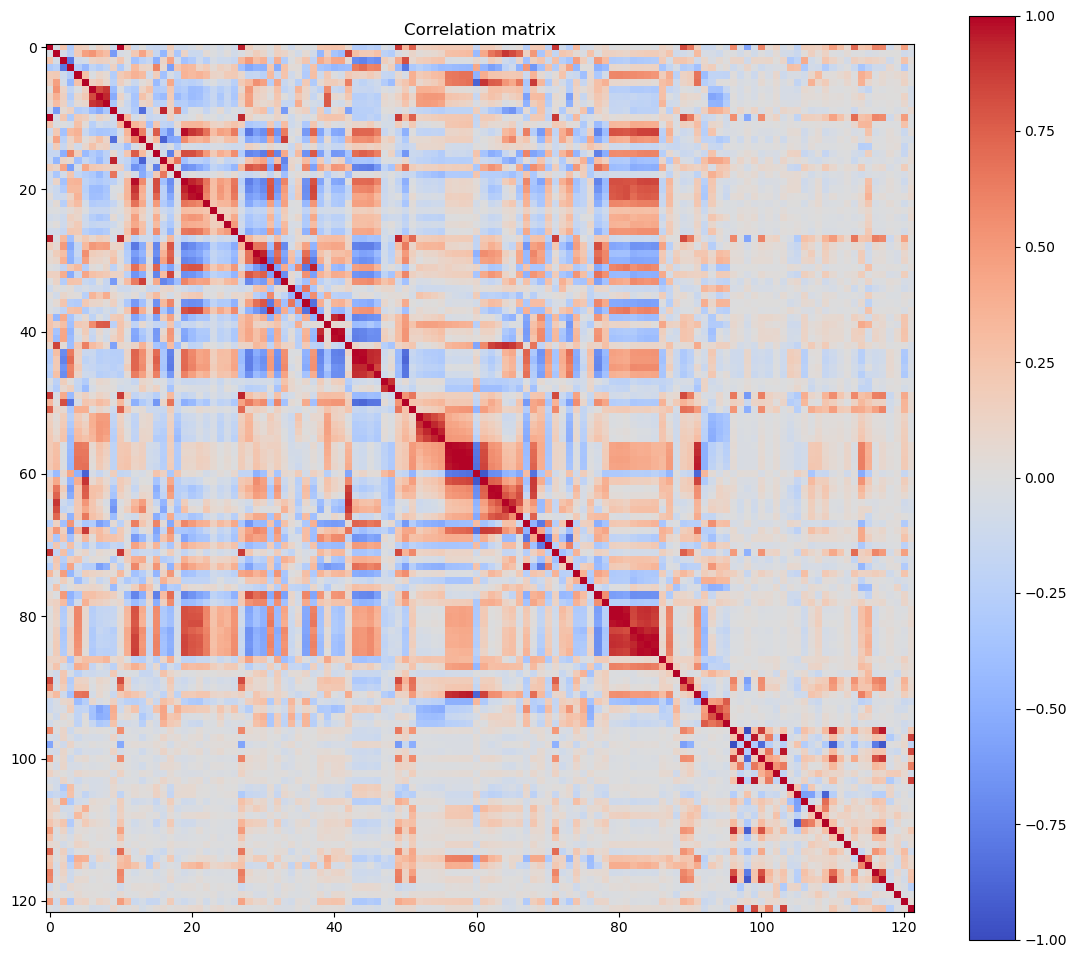

In [10]:
X_all = pd.concat([X_train, X_test])
corr_matrix = X_all.corr()

plt.figure(figsize=(14, 12))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.title("Correlation matrix")
plt.show()

### (d)

Calculate the Coefficient of Variation CV for each feature.

In [11]:
# std() uses the sample standard deviation (ddof=1)
cv_values = X_all.std() / X_all.mean()
cv_values = cv_values.sort_values(ascending=False)
cv_values

NumStreet              4.407702
NumInShelters          3.485481
NumIlleg               2.994196
NumImmig               2.900497
LemasPctOfficDrugUn    2.555266
                         ...   
NumKindsDrugsSeiz      0.146867
RacialMatchCommPol     0.132619
PctPolicWhite          0.121894
LemasPctPolicOnPatr    0.120471
LemasSwFTFieldOps      0.057457
Length: 122, dtype: float64

### (e)

Pick √128 features with highest CV , and make scatter plots and box plots for
them. Can you draw conclusions about significance of those features, just by the
scatter plots?

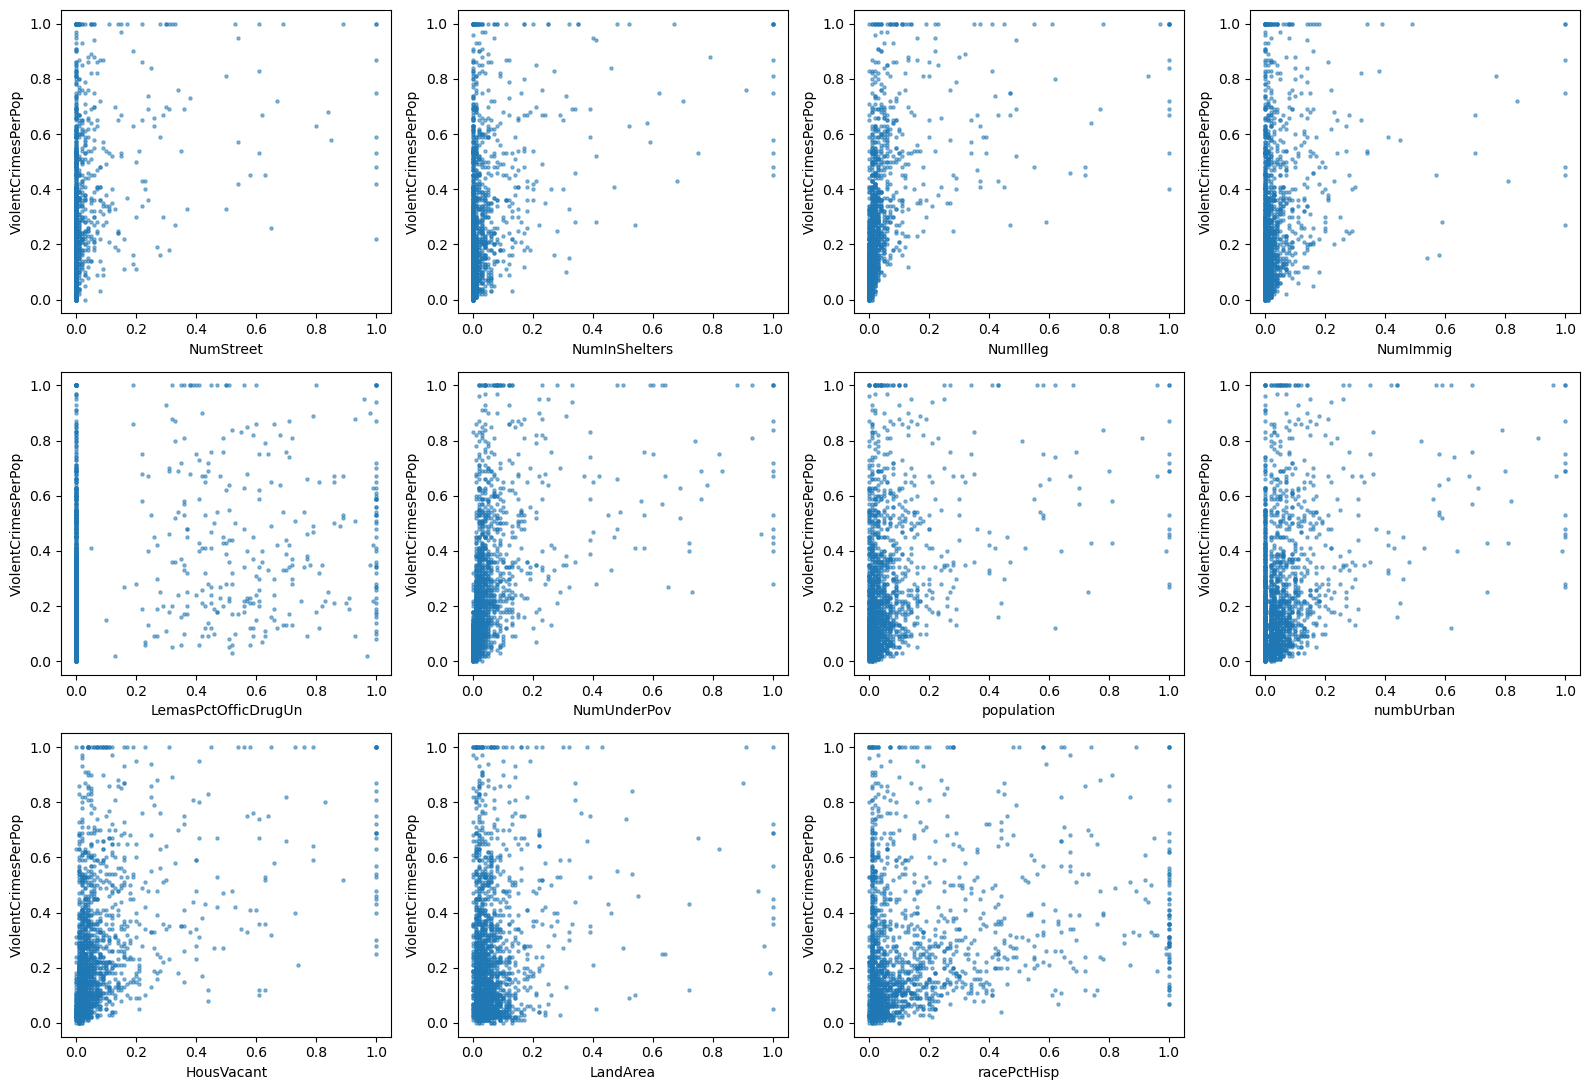

In [12]:
top_features = cv_values.index[:11]
y_all = pd.concat([y_train, y_test])

# scatter plot of each feature vs the target
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()
for i, feature in enumerate(top_features):
    axes[i].scatter(X_all[feature], y_all, s=5, alpha=0.5)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("ViolentCrimesPerPop")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

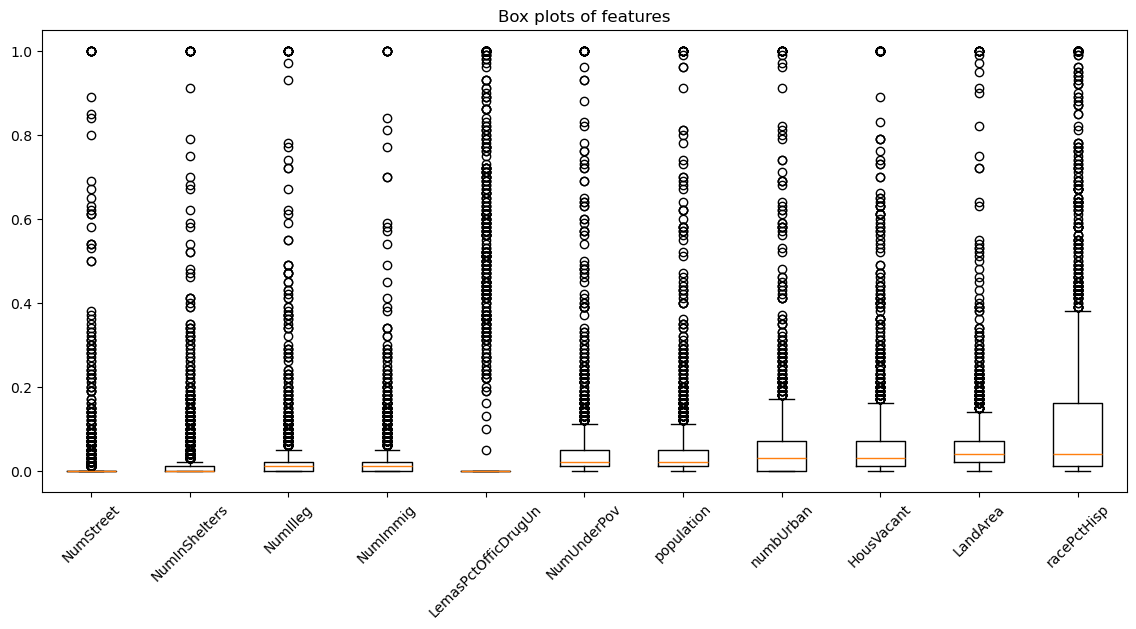

In [13]:
# box plots
plt.figure(figsize=(14, 6))
plt.boxplot(X_all[top_features], tick_labels=top_features)
plt.xticks(rotation=45)
plt.title("Box plots of features")
plt.show()

**2(e) answer**

We couldn't draw conclusions about significance of those features, just by the scatter plots, becasuce Scatter plots shows the marginal relationship between one feature and the target. Access significance requires statistical test.

### (f)

Fit a linear model using least squares to the training set and report the test error.

In [14]:
# train model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
# get test error
linear_test_error = mean_squared_error(y_test, linear_model.predict(X_test))
print("Test error:", linear_test_error)

Test error: 0.018141971135530104


### (g)

Fit a ridge regression model on the training set

In [15]:
# choose lambda with 5-fold CV
ridge_model = RidgeCV(alphas=np.logspace(-3, 3, 100), cv=5)
ridge_model.fit(X_train, y_train)
# get test error
ridge_test_error = mean_squared_error(y_test, ridge_model.predict(X_test))
print("Test error:", ridge_test_error)

Test error: 0.017610091710140947


### (h)

Fit a LASSO model on the training set

In [16]:
# choose lambda with 5-fold CV
lasso_model = LassoCV(cv=5, random_state=0, max_iter=10000)
# fit LASSO
lasso_model.fit(X_train, y_train)
lasso_test_error = mean_squared_error(y_test, lasso_model.predict(X_test))
lasso_selected = X_train.columns[lasso_model.coef_ != 0]
print("Test error:", lasso_test_error)
print("variables selected by LASSO :",list(lasso_selected))

Test error: 0.017758209216319674
variables selected by LASSO : ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctBornSa

In [17]:
# standardize features
scaler = StandardScaler()
scaler.fit(X_train)
X_train_std = scaler.transform(X_train)
X_test_std = scaler.transform(X_test)
# repeat
lasso_model_std = LassoCV(cv=5, random_state=0, max_iter=10000)
lasso_model_std.fit(X_train_std, y_train)
lasso_test_error_std = mean_squared_error(y_test, lasso_model_std.predict(X_test_std))
lasso_selected_std = X_train.columns[lasso_model_std.coef_ != 0]
print("Test error:", lasso_test_error_std)
print("variables selected by LASSO :", list(lasso_selected_std))

Test error: 0.01780533927686227
variables selected by LASSO : ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctSameCity85', 'LemasSwFTFieldPerPop', 

**2(h) answer**

The original Test error of LASSO is 0.01776. After standardizing features, the test error became 0.01781. The two test errors are almost the same.

### (i)

Fit a PCR model on the training set, with $M$ (the number of principal components) chosen by cross-validation. Report the test error obtained.

In [18]:
# standardize -> PCA -> linear regression
pcr = make_pipeline(StandardScaler(), PCA(), LinearRegression())
param_grid = {"pca__n_components": range(1, X_train.shape[1] + 1)}
# choose M with 5-fold CV
grid = GridSearchCV(pcr, param_grid, cv=5, scoring="neg_mean_squared_error")
grid.fit(X_train, y_train)
# get test error
pcr_test_error = mean_squared_error(y_test, grid.predict(X_test))
print("Test error:", pcr_test_error)

Test error: 0.018392931230387776


### (j)

Fit an L1 penalized gradient boosting tree with XGBoost. 

In [19]:
xgb = XGBRegressor(random_state=0)
param_grid = {"reg_alpha": np.logspace(-3, 3, 20)}
# choose alpha with 5-fold CV
grid = GridSearchCV(xgb, param_grid, cv=5, scoring="neg_mean_squared_error")
grid.fit(X_train, y_train)
xgb_test_error = mean_squared_error(y_test, grid.predict(X_test))
print("the regularization term:", grid.best_params_["reg_alpha"])
print("Test error:", xgb_test_error)

the regularization term: 6.158482110660261
Test error: 0.01684617523244343
